# 06 - Results and statistics

Compare clean, attacked and defended performance using the saved predictions.

**Inputs:** Prediction files from previous notebooks.  
**Outputs:** Metrics in `artifacts/tables/` and plots in `artifacts/figures/`.


## Load the setup and define the scores

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import accuracy_score, f1_score

# Same path setup as notebook 00; repeated for independent execution.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text(encoding='utf-8'))

PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
for directory in (PATHS['tables'],):
    directory.mkdir(parents=True, exist_ok=True)

def condition_metric_rows(frame):
    keys = ['dataset', 'model', 'model_seed', 'attack', 'strength', 'attack_seed', 'defense']
    #match attacked rows to the same examples before attack, under this defense
    clean = frame[frame['attack'] == 'clean'].set_index('example_id')['correct']
    if not clean.index.is_unique:
        raise ValueError('Duplicate clean example IDs')
    rows = []
    for values, group in frame.groupby(keys, dropna=False, observed=True):
        row = dict(zip(keys, values))
        row.update({
            'n': len(group),
            'accuracy': accuracy_score(group['gt_label'], group['prediction']),
            'macro_f1': f1_score(group['gt_label'], group['prediction'], average='macro', zero_division=0),
            'coverage': float((group['changed_count'] > 0).mean()),
        })
        if row['attack'] == 'clean':
            row['attack_success_rate'] = 0.0
        else:
            aligned_clean = clean.reindex(group['example_id'])
            if aligned_clean.isna().any():
                raise ValueError('Missing clean prediction for an attacked example')
            aligned_clean = aligned_clean.to_numpy(dtype=bool)
            attacked_correct = group['correct'].to_numpy(dtype=bool)
            denominator = aligned_clean.sum()
            row['attack_success_rate'] = float((aligned_clean & ~attacked_correct).sum() / denominator) if denominator else np.nan
        rows.append(row)
    return rows


## Score each condition and summarize the results


In [2]:
prediction_files = sorted(PATHS['predictions'].glob('**/*.parquet'))
if not prediction_files:
    raise FileNotFoundError('No prediction artifacts found, be sure to have run previous notebooks first')
seed_rows = []
for path in prediction_files:
    frame = pd.read_parquet(path)
    seed_rows.extend(condition_metric_rows(frame))

seed_metrics = pd.DataFrame(seed_rows)
seed_metrics.to_csv(PATHS['tables'] / 'condition_metrics_by_seed.csv', index=False)

group_keys = ['dataset', 'model', 'attack', 'strength', 'defense']
metric_columns = ['accuracy', 'macro_f1', 'attack_success_rate', 'coverage']
summary = seed_metrics.groupby(group_keys, as_index=False).agg(
    runs=('accuracy', 'size'),
    **{f'{metric}_mean': (metric, 'mean') for metric in metric_columns},
    **{f'{metric}_std': (metric, 'std') for metric in metric_columns},
)
#one run has zero displayed spread; an undefined metric stays undefined
for metric in metric_columns:
    defined = summary[f'{metric}_mean'].notna()
    summary.loc[defined, f'{metric}_std'] = summary.loc[defined, f'{metric}_std'].fillna(0.0)

clean = summary[summary['attack'] == 'clean'][['dataset', 'model', 'defense', 'accuracy_mean', 'macro_f1_mean']].rename(columns={'accuracy_mean': 'clean_accuracy', 'macro_f1_mean': 'clean_macro_f1'})
summary = summary.merge(clean, on=['dataset', 'model', 'defense'], how='left', validate='many_to_one')
summary['accuracy_drop'] = summary['clean_accuracy'] - summary['accuracy_mean']
summary['macro_f1_drop'] = summary['clean_macro_f1'] - summary['macro_f1_mean']

raw = summary[summary['defense'] == 'none'][['dataset', 'model', 'attack', 'strength', 'accuracy_mean', 'macro_f1_mean', 'clean_accuracy', 'clean_macro_f1']].rename(columns={'accuracy_mean': 'raw_attacked_accuracy', 'macro_f1_mean': 'raw_attacked_macro_f1', 'clean_accuracy': 'raw_clean_accuracy', 'clean_macro_f1': 'raw_clean_macro_f1'})
summary = summary.merge(raw, on=['dataset', 'model', 'attack', 'strength'], how='left', validate='many_to_one')
for metric in ['accuracy', 'macro_f1']:
    denominator = summary[f'raw_clean_{metric}'] - summary[f'raw_attacked_{metric}']
    numerator = summary[f'{metric}_mean'] - summary[f'raw_attacked_{metric}']
    summary[f'{metric}_defense_recovery'] = np.where(denominator > 0, numerator / denominator, np.nan)
    summary[f'{metric}_clean_delta'] = summary[f'clean_{metric}'] - summary[f'raw_clean_{metric}']
summary.to_csv(PATHS['tables'] / 'metrics_summary.csv', index=False)


## Clean, attacked and defended performance

The attack and defense tables use 20% strength and weight the four effective families equally. Composition is excluded because it changes no inputs. Recovery averages only defined family ratios; `recovery_families` counts how many contribute. Sample count `n` refers to original test examples.


In [3]:
from IPython.display import display

n = seed_metrics.groupby(['dataset', 'model'], as_index=False)['n'].first()
clean = summary[(summary.attack == 'clean') & (summary.defense == 'none')]
display(clean.merge(n, on=['dataset', 'model'])[
    ['dataset', 'model', 'n', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'macro_f1_std']].round(3))

families = ['homoglyph', 'invisible', 'compatibility', 'mixed']
primary = summary[summary.strength.eq(CONFIG['analysis']['primary_strength']) & summary.attack.isin(families)]
attacked = primary[primary.defense.eq('none')].groupby(['dataset', 'model'], as_index=False)[
    ['accuracy_mean', 'macro_f1_mean', 'macro_f1_drop', 'attack_success_rate_mean', 'coverage_mean']].mean()
display(attacked.merge(n, on=['dataset', 'model']).round(3))

defenses = primary[primary.defense.ne('none')].groupby(['dataset', 'model', 'defense'], as_index=False).agg(
    macro_f1=('macro_f1_mean', 'mean'), recovery=('macro_f1_defense_recovery', 'mean'),
    recovery_families=('macro_f1_defense_recovery', 'count'), clean_delta=('macro_f1_clean_delta', 'first'))
display(defenses.round(3))


,dataset,model,n,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,banking77,bpe_tfidf,3080,0.882,0.000,0.882,0.000
1,banking77,char_tfidf,3080,0.906,0.000,0.906,0.000
2,banking77,distilbert,3080,0.832,0.003,0.819,0.004
3,banking77,word_tfidf,3080,0.885,0.000,0.886,0.000
4,trec,bpe_tfidf,500,0.890,0.000,0.879,0.000
5,trec,char_tfidf,500,0.888,0.000,0.883,0.000
6,trec,distilbert,500,0.967,0.003,0.944,0.009
7,trec,word_tfidf,500,0.888,0.000,0.885,0.000


,dataset,model,accuracy_mean,macro_f1_mean,macro_f1_drop,attack_success_rate_mean,coverage_mean,n
0,banking77,bpe_tfidf,0.496,0.496,0.386,0.453,1.0,3080
1,banking77,char_tfidf,0.806,0.807,0.099,0.125,1.0,3080
2,banking77,distilbert,0.502,0.498,0.321,0.408,1.0,3080
3,banking77,word_tfidf,0.467,0.466,0.420,0.490,1.0,3080
4,trec,bpe_tfidf,0.505,0.447,0.432,0.454,1.0,500
5,trec,char_tfidf,0.752,0.759,0.124,0.179,1.0,500
6,trec,distilbert,0.710,0.701,0.243,0.274,1.0,500
7,trec,word_tfidf,0.569,0.537,0.347,0.386,1.0,500


,dataset,model,defense,macro_f1,recovery,recovery_families,clean_delta
0,banking77,bpe_tfidf,nfc,0.496,0.000,4,0.0
1,banking77,bpe_tfidf,nfkc,0.632,0.292,4,0.0
2,banking77,bpe_tfidf,nfkc_strip,0.803,0.724,4,0.0
3,banking77,bpe_tfidf,nfkc_strip_confusable,0.882,1.000,4,0.0
4,banking77,bpe_tfidf,strip_ignorables,0.667,0.431,4,0.0
5,banking77,char_tfidf,nfc,0.807,0.000,4,0.0
6,banking77,char_tfidf,nfkc,0.850,0.310,4,0.0
7,banking77,char_tfidf,nfkc_strip,0.884,0.723,4,0.0
8,banking77,char_tfidf,nfkc_strip_confusable,0.906,1.000,4,0.0
9,banking77,char_tfidf,strip_ignorables,0.843,0.427,4,0.0


## What happens when we turn up the attack strength?


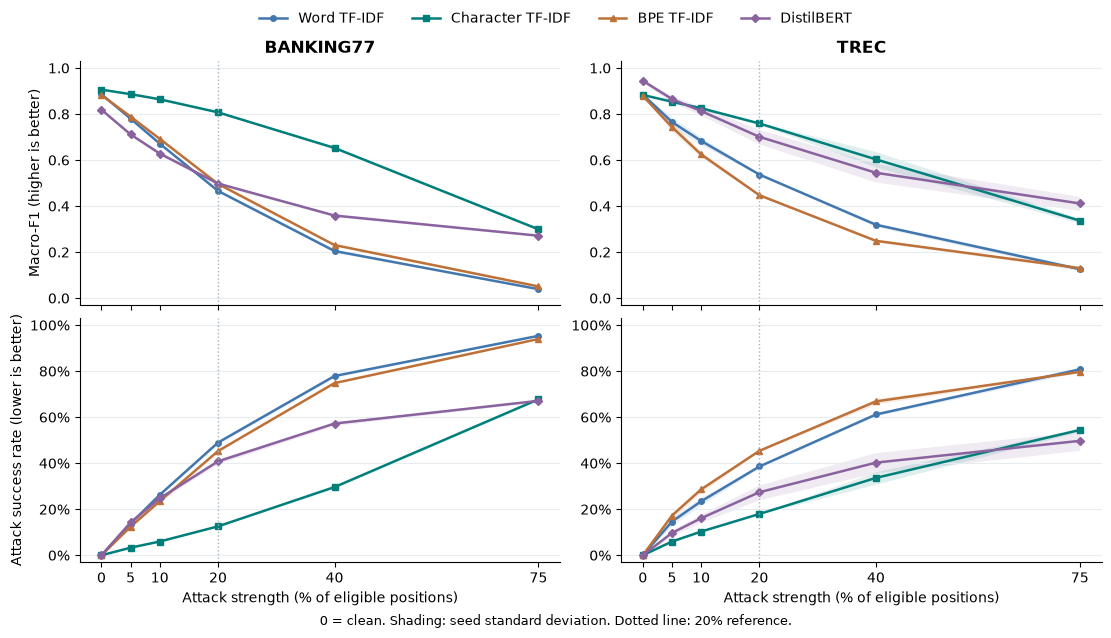

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

models = ['word_tfidf', 'char_tfidf', 'bpe_tfidf', 'distilbert']
model_labels = dict(zip(models, ['Word TF-IDF', 'Character TF-IDF', 'BPE TF-IDF', 'DistilBERT']))
colors = dict(zip(models, ['#4277AE', '#007F7A', '#BD7138', '#8A629E']))
markers = dict(zip(models, ['o', 's', '^', 'D']))
datasets = ['banking77', 'trec']
metrics = ['macro_f1', 'attack_success_rate']
raw_scores = seed_metrics[seed_metrics.defense.eq('none') & seed_metrics.attack.isin(families)]
#each run must contain all four families, otherwise the averages wouldn't be comparable
run_keys = ['dataset', 'model', 'model_seed', 'attack_seed', 'strength']
assert raw_scores.groupby(run_keys).attack.nunique().eq(len(families)).all(), 'Incomplete attack families'
run_averages = raw_scores.groupby(run_keys, as_index=False)[metrics].mean()
strength_scores = run_averages.groupby(['dataset', 'model', 'strength'])[metrics].agg(['mean', 'std'])
clean_scores = summary[summary.defense.eq('none') & summary.attack.eq('clean')].set_index(['dataset', 'model'])
strengths = sorted(raw_scores.strength.unique())

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})
PATHS['figures'].mkdir(parents=True, exist_ok=True)

def save_plot(fig, name):
    fig.savefig(PATHS['figures'] / name, dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.3), sharex=True, constrained_layout=True)
for column, dataset in enumerate(datasets):
    for row, metric in enumerate(metrics):
        ax = axes[row, column]
        for model in models:
            values = strength_scores.loc[(dataset, model)].sort_index()
            #prepend the actual clean result, then only plot measured attack strengths
            x = np.r_[0, values.index.to_numpy() * 100]
            y = np.r_[clean_scores.loc[(dataset, model), f'{metric}_mean'], values[metric, 'mean']]
            sd = np.r_[clean_scores.loc[(dataset, model), f'{metric}_std'], values[metric, 'std'].fillna(0)]
            ax.plot(x, y, color=colors[model], marker=markers[model], ms=4, lw=1.8, label=model_labels[model])
            ax.fill_between(x, y-sd, y+sd, color=colors[model], alpha=.12, linewidth=0)
        ax.set(title=dataset.upper() if row == 0 else '', ylim=(-.03, 1.03))
        ax.axvline(20, color='#A6B4BE', ls=':', lw=1)
        ax.grid(axis='y', color='#E7ECEF')
        if row == 1:
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.set_xlabel('Attack strength (% of eligible positions)')
        ax.set_xticks([0] + [s*100 for s in strengths], ['0'] + [f'{s*100:g}' for s in strengths])
axes[0, 0].set_ylabel('Macro-F1 (higher is better)')
axes[1, 0].set_ylabel('Attack success rate (lower is better)')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside upper center', ncol=4, frameon=False)
fig.supxlabel('0 = clean. Shading: seed standard deviation. Dotted line: 20% reference.', fontsize=9)
save_plot(fig, 'attack_strength_overview.png')


## Which attack causes the drop?

Each panel follows one attack family across strengths, with the clean score as a reference. Composition is excluded because it changes no inputs.


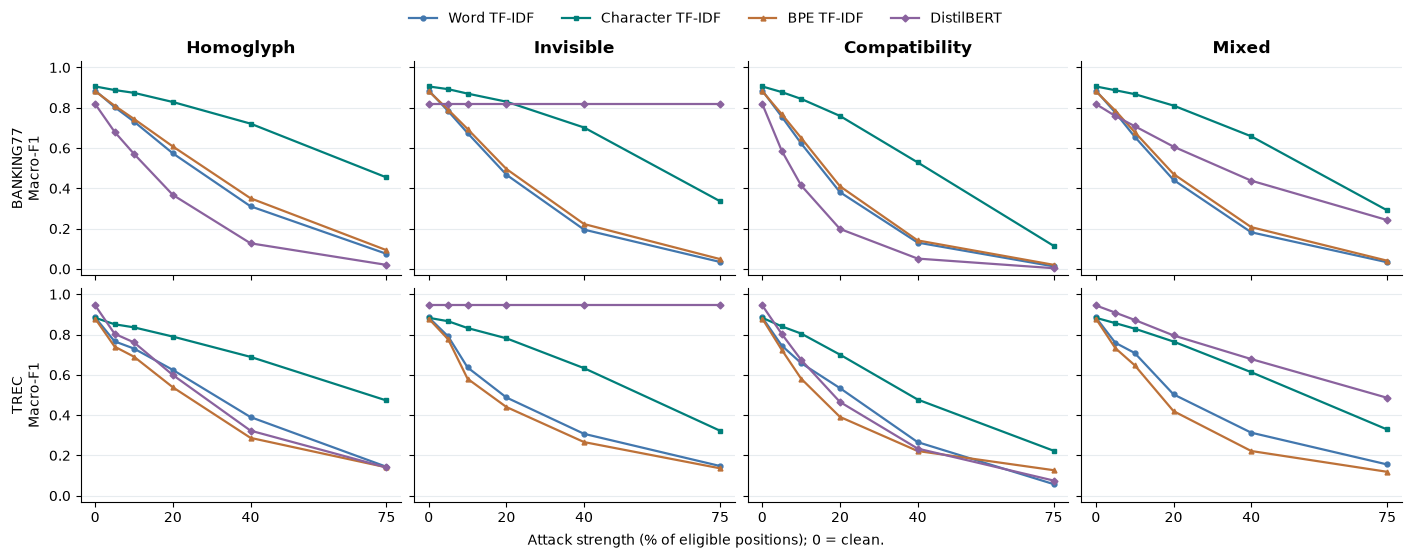

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True, sharey=True, constrained_layout=True)
for row, dataset in enumerate(datasets):
    for column, attack in enumerate(families):
        ax = axes[row, column]
        for model in models:
            values = summary[summary.dataset.eq(dataset) & summary.model.eq(model)
                             & summary.defense.eq('none') & summary.attack.eq(attack)].sort_values('strength')
            x = np.r_[0, values.strength.to_numpy() * 100]
            y = np.r_[clean_scores.loc[(dataset, model), 'macro_f1_mean'], values.macro_f1_mean]
            ax.plot(x, y, color=colors[model], marker=markers[model], ms=3.5, lw=1.6, label=model_labels[model])
        ax.set(title=attack.title() if row == 0 else '', ylim=(-.03, 1.03))
        ax.grid(axis='y', color='#E7ECEF')
        ax.set_xticks([0, 20, 40, 75])
        if column == 0:
            ax.set_ylabel(f'{dataset.upper()}\nMacro-F1')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside upper center', ncol=4, frameon=False)
fig.supxlabel('Attack strength (% of eligible positions); 0 = clean.', fontsize=10)
save_plot(fig, 'attack_strength_by_family.png')


## Compare the stronger attacks directly

Macro-F1 at 20%, 40% and 75%, averaged equally across the four effective attack families.


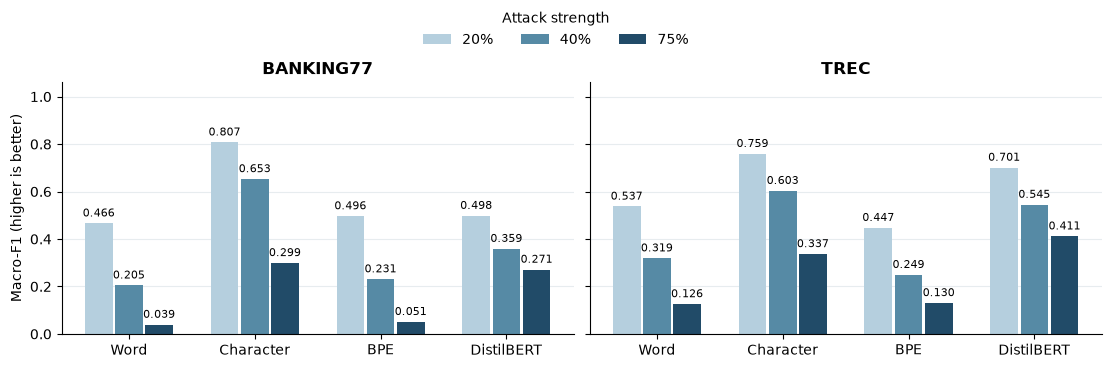

In [6]:
bar_strengths = [0.20, 0.40, 0.75]
bar_colors = ['#B5CFDE', '#568AA5', '#214B68']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, constrained_layout=True)
for ax, dataset in zip(axes, datasets):
    for i, (strength, color) in enumerate(zip(bar_strengths, bar_colors)):
        #reindex leaves missing model/strength combinations as NaN
        values = strength_scores.xs((dataset, strength), level=('dataset', 'strength'))[('macro_f1', 'mean')].reindex(models)
        x = np.arange(len(models)) + (i-1) * .24
        bars = ax.bar(x, values.to_numpy(), width=.22, color=color, label=f'{strength:.0%}')
        ax.bar_label(bars, labels=[f'{v:.3f}' if pd.notna(v) else '' for v in values], padding=3, fontsize=8)
        for position, value in zip(x, values):
            if pd.isna(value):
                ax.text(position, .025, 'N/A', ha='center', va='bottom', rotation=90, fontsize=8, color='#586779')
    ax.set(title=dataset.upper(), ylim=(0, 1.06), xticks=range(len(models)),
           xticklabels=['Word', 'Character', 'BPE', 'DistilBERT'])
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#E7ECEF')
axes[0].set_ylabel('Macro-F1 (higher is better)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside upper center', ncol=3, frameon=False, title='Attack strength')
save_plot(fig, 'strong_attack_comparison.png')
